# Практическое занятие № 11 — алгоритмы классификации
**ТюмГУ · Технологии искусственного интеллекта — 1 · 90 минут**  
Кейс: риск задержки доставки более 15 минут.  
**Цель:** сопоставить DecisionTree, RandomForest, GradientBoosting с Dummy и LogisticRegression на идентичных выборках, изучить глубину дерева и интерпретацию.

**Файлы:** загрузите `orders_dirty.csv` (ваш учебный набор) и при наличии `split_ids_06.csv`. Допустимые данные и их очистка должны совпадать с практиками 6–10. `actual_minutes`, `late`, `order_id` запрещены в X. Начальный блок учебный и воспроизводимый; самостоятельно объясните каждый этап в отчёте.

## 1. Подготовить данные и проверить инварианты (0–15 мин)
1. Запишите форму сырого набора и N после очистки.
2. Зафиксируйте доли классов по train/val; не исследуйте test до завершения настройки модели.
3. Сверьте CSV-файлы разбиения с материалами занятия № 6. Если разбивка не сохранена, генератор воспроизводит случайное стратифицированное разбиение `random_state=42`.
4. Объясните, почему нельзя использовать фактическую длительность доставки как ранний предиктор.

In [2]:
# Общая подготовка для практик 11 и 12
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PATH = Path('orders_dirty.csv')
if not PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv в файлы Colab или измените PATH.')

df_raw = pd.read_csv(PATH, encoding='utf-8-sig')
expected = {'order_id','created_at','distance_km','zone','queue_size',
            'weather','promised_minutes','actual_minutes','late'}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f'Отсутствуют необходимые поля: {sorted(missing_cols)}'
print('Сырой набор:', df_raw.shape, '; полные дубликаты:', int(df_raw.duplicated().sum()))
if 'courier_load' not in df_raw.columns:
    # Поле есть в методичке, но отсутствует в фактическом источнике практик 5–10.
    # Не восстанавливаем значения по целевой переменной или другим косвенным данным.
    df_raw['courier_load'] = np.nan
    print('courier_load отсутствует в источнике: все значения NaN; признак неинформативен.')

# Удаление полных повторов: не обучаем статистику и не используем test.
df = df_raw.drop_duplicates().copy()
df['late'] = pd.to_numeric(df['late'], errors='coerce')
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
valid_rule = actual.notna() & promised.notna() & df['late'].isin([0, 1])
conflict = valid_rule & (df['late'] != ((actual - promised) > 15).astype(int))
print('Конфликтных меток (проверяемых):', int(conflict.sum()))
df = df.loc[~conflict & df['late'].isin([0, 1])].copy()
df['late'] = df['late'].astype(int)
# Неполные / конфликтные сведения об идентификаторе требуют отдельного решения.
assert df['order_id'].notna().all(), 'Обнаружены пустые ID заказов.'
assert not df['order_id'].duplicated().any(), 'Есть повторные ID: требуется анализ причины, не случайное удаление.'
print('После удаления полных повторов:', len(df_raw.drop_duplicates()))
print('Рабочая копия:', df.shape)
print('Исключено строк с недопустимой меткой:', int((~df_raw.drop_duplicates()['late'].isin([0, 1])).sum()))

split_path = Path('split_ids_06.csv')  # Необязательный экспорт из практики № 6
if split_path.exists():
    splits = pd.read_csv(split_path, dtype={'order_id': str})
    assert {'order_id', 'split'} <= set(splits.columns)
    assert set(splits['split']) <= {'train', 'val', 'test'}
    assert splits['order_id'].is_unique
    x = df.assign(order_id=df['order_id'].astype(str)).merge(
        splits[['order_id', 'split']], on='order_id', how='left', validate='one_to_one')
    assert x['split'].notna().all(), 'В split_ids_06.csv перечислены не все рабочие заказы.'
    assert set(splits['order_id']) == set(x['order_id'])
    train = x.loc[x['split'] == 'train'].drop(columns='split').copy()
    val   = x.loc[x['split'] == 'val'].drop(columns='split').copy()
    test  = x.loc[x['split'] == 'test'].drop(columns='split').copy()
else:
    # Воссоздание схемы практики № 6, если файл с IDs не был сохранён.
    train_dev, test = train_test_split(df, test_size=.20, stratify=df['late'], random_state=42)
    train, val = train_test_split(train_dev, test_size=.25,
                                 stratify=train_dev['late'], random_state=42)
    split_export = pd.concat([
       train[['order_id']].assign(split='train'),
       val[['order_id']].assign(split='val'),
       test[['order_id']].assign(split='test')], ignore_index=True)
    split_export.to_csv('split_ids_06.csv', index=False)

sets = [set(a['order_id']) for a in (train, val, test)]
assert len(sets[0]&sets[1]) == len(sets[0]&sets[2]) == len(sets[1]&sets[2]) == 0
assert sets[0]|sets[1]|sets[2] == set(df['order_id'])
assert len(train)+len(val)+len(test) == len(df)
print('train / val / test:', len(train), len(val), len(test))
print('Доли от рабочего N:', [round(len(a)/len(df), 4) for a in (train, val, test)])
print('late=1 на train и validation:', round(train['late'].mean(), 4), round(val['late'].mean(), 4))
print('Утечка фактической длительности недопустима: actual_minutes становится известна после доставки.')

Сырой набор: (600, 10) ; полные дубликаты: 1
courier_load отсутствует в источнике: все значения NaN; признак неинформативен.
Конфликтных меток (проверяемых): 1
После удаления полных повторов: 599
Рабочая копия: (598, 11)
Исключено строк с недопустимой меткой: 0
train / val / test: 358 120 120
Доли от рабочего N: [0.5987, 0.2007, 0.2007]
late=1 на train и validation: 0.4693 0.4667
Утечка фактической длительности недопустима: actual_minutes становится известна после доставки.


## 2. Признаки и конвейер (15–25 мин)
Ни один кодировщик или заполнитель пропусков не должен обучаться до разделения данных. Производные признаки: час в циклическом представлении и ожидаемая средняя скорость. Проверьте схему и трансформацию.

In [3]:
# В Colab функция экспортируется в обычный модуль для безопасного joblib.dump.
# При перезапуске блокнота модуль восстанавливается автоматически.
from pathlib import Path
Path('tyumgu_feature_rules.py').write_text("# Правила преобразования признаков для занятий 7–12\nimport numpy as np\nimport pandas as pd\nNUM_BASE = ['distance_km', 'queue_size', 'courier_load', 'promised_minutes']\nCAT = ['zone', 'weather']\nNUM = NUM_BASE + ['hour_sin', 'hour_cos', 'planned_speed_kmh']\nINPUT = NUM_BASE + CAT + ['created_at']\n\ndef make_features(X):\n    f = X.loc[:, INPUT].copy()\n    for name in NUM_BASE:\n        f[name] = pd.to_numeric(f[name], errors='coerce')\n    for name in NUM_BASE:\n        f.loc[f[name] < 0, name] = np.nan\n    f.loc[f['promised_minutes'] == 0, 'promised_minutes'] = np.nan\n    for name in CAT:\n        s = f[name].astype('string').str.strip()\n        s = s.mask(s.str.lower().isin(['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))\n        f[name] = s.astype(object).where(s.notna(), np.nan)\n    time = pd.to_datetime(f['created_at'], errors='coerce')\n    hour = time.dt.hour.astype(float)\n    f['hour_sin'] = np.sin(2*np.pi*hour/24)\n    f['hour_cos'] = np.cos(2*np.pi*hour/24)\n    f['planned_speed_kmh'] = 60*f['distance_km']/f['promised_minutes']\n    f['planned_speed_kmh'] = f['planned_speed_kmh'].replace([np.inf, -np.inf], np.nan)\n    return f.drop(columns='created_at')\n", encoding='utf-8')
from tyumgu_feature_rules import NUM_BASE, NUM, CAT, INPUT, make_features
F_train, F_val = [make_features(part) for part in (train, val)]
assert set(F_train.columns) == set(NUM + CAT)
assert all(col not in F_train.columns for col in ('late','actual_minutes','order_id'))
print('Матрица до кодирования:', F_train.shape)
print('Числовые столбцы:', NUM, '; категориальные:', CAT)

Матрица до кодирования: (358, 9)
Числовые столбцы: ['distance_km', 'queue_size', 'courier_load', 'promised_minutes', 'hour_sin', 'hour_cos', 'planned_speed_kmh'] ; категориальные: ['zone', 'weather']


In [4]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

numeric_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='median', add_indicator=True,
                           keep_empty_features=True)),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='неизвестно')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, NUM),
    ('cat', cat_pipe, CAT)
], remainder='drop', verbose_feature_names_out=True)

def build_pipeline(classifier):
    return Pipeline([
        ('derive', FunctionTransformer(make_features, validate=False)),
        ('prep', clone(preprocess)),
        ('clf', classifier)
    ])

Xtrain = train[INPUT].copy(); Xval = val[INPUT].copy()
ytrain = train['late'].astype(int).copy()
yval = val['late'].astype(int).copy()
# test хранится отдельно и не используется для подбора модели.
assert ytrain.nunique() == 2, 'Для обучения необходимы 0 и 1 в train.'
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtrain.columns)
assert set(train['order_id']).isdisjoint(val['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(val['order_id']).isdisjoint(test['order_id'])
print('Обучение:', Xtrain.shape, '| validation:', Xval.shape,
      '| отложенный test:', len(test))
probe = build_pipeline(DummyClassifier(strategy='prior')).named_steps['prep']
probe.fit(F_train, ytrain)
print('Признаков до/после кодирования:', F_train.shape[1], len(probe.get_feature_names_out()))
assert len(probe.get_feature_names_out()) > F_train.shape[1]
print('Доли класса late=1 (train / validation):',
      [round(v.mean(), 3) for v in (ytrain,yval)])

Обучение: (358, 7) | validation: (120, 7) | отложенный test: 120
Признаков до/после кодирования: 9 18
Доли класса late=1 (train / validation): [np.float64(0.469), np.float64(0.467)]


## 3. Обучить пять моделей на одних данных (25–43 мин)
Сравните Dummy, логистическую регрессию, одиночное дерево, случайный лес и градиентный бустинг. Параметры указывайте вместе с обоснованием; здесь даны стартовые учебные значения.

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Одинаковый препроцессинг и те же train / validation для честного сравнения.
# Названия и параметры фиксированы ДО анализа test.
CANDIDATES = {
    'Dummy': DummyClassifier(strategy='prior'),
    'LogReg': LogisticRegression(C=1, max_iter=3000, random_state=42),
    'Tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42),
    'Forest': RandomForestClassifier(n_estimators=120, max_depth=6,
                                      min_samples_leaf=3, random_state=42,
                                      n_jobs=-1),
    'Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                            max_depth=2, min_samples_leaf=3,
                                            random_state=42)
}

models = {}
for name, estimator in CANDIDATES.items():
    model = build_pipeline(estimator)
    model.fit(Xtrain, ytrain)  # Только train!
    models[name] = model
    assert len(model.predict(Xval)) == len(yval)
print('Обучены:', ', '.join(models))

Обучены: Dummy, LogReg, Tree, Forest, Boosting


## 4. Сопоставить результаты на validation (43–57 мин)
Представьте `F1`, `balanced_accuracy`, ROC-AUC и AP (Average Precision). Последнее — *не тождественно трапециевидной площади* под PR-кривой. Если класс 1 отсутствует на val, ROC-AUC не определена; требуется дополнительное обоснование разбиения.

**Самостоятельно:** укажите лучшую модель по двум различным критериям; объясните, почему лидеры могут не совпадать.

In [6]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
    RocCurveDisplay, PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

def positives(model, X):
    # При чтении вероятностей проверяем позицию именно класса 1.
    classes = model.named_steps['clf'].classes_
    ix = int(np.flatnonzero(classes == 1)[0])
    return model.predict_proba(X)[:, ix]

def metrics_at(y, p, threshold=0.50, model_name=''):
    y = np.asarray(y).astype(int)
    pred = (np.asarray(p) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    d = {
        'model': model_name, 'threshold': float(threshold),
        'N': len(y), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'accuracy': accuracy_score(y, pred),
        'balanced_accuracy': balanced_accuracy_score(y, pred),
        'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'cost_rub': 200 * int(fp) + 2000 * int(fn)
    }
    if len(np.unique(y)) == 2:
        d['roc_auc'] = roc_auc_score(y, p)
        d['average_precision'] = average_precision_score(y, p)
    else:
        d['roc_auc'] = float('nan')
        d['average_precision'] = float('nan')
    return d

In [7]:
rows = []
for name, m in models.items():
    prob = positives(m, Xval)
    rows.append(metrics_at(yval, prob, model_name=name))
val_results = pd.DataFrame(rows).sort_values(['f1','average_precision'], ascending=False)
display(val_results.round(3))
val_results.to_csv('11_validation_models.csv', index=False)
assert set(val_results['model']) == set(CANDIDATES)
assert val_results['N'].eq(len(val)).all()
f1_best = val_results.loc[val_results['f1'].idxmax()]
ap_best = val_results.loc[val_results['average_precision'].idxmax()]
print(f"Лидер по F1: {f1_best['model']} ({f1_best['f1']:.3f}); "
      f"по AP: {ap_best['model']} ({ap_best['average_precision']:.3f}).")
print('F1 использует решения при пороге 0.5; ROC-AUC и AP — все вероятностные оценки,')
print('поэтому порядок моделей по этим критериям может различаться.')


,model,threshold,N,TN,FP,FN,TP,accuracy,balanced_accuracy,precision,recall,f1,cost_rub,roc_auc,average_precision
1,LogReg,0.5,120,49,15,19,37,0.717,0.713,0.712,0.661,0.685,41000,0.755,0.741
3,Forest,0.5,120,42,22,17,39,0.675,0.676,0.639,0.696,0.667,38400,0.744,0.763
2,Tree,0.5,120,43,21,22,34,0.642,0.640,0.618,0.607,0.613,48200,0.654,0.626
4,Boosting,0.5,120,42,22,22,34,0.633,0.632,0.607,0.607,0.607,48400,0.680,0.693
0,Dummy,0.5,120,64,0,56,0,0.533,0.500,0.000,0.000,0.000,112000,0.500,0.467


Лидер по F1: LogReg (0.685); по AP: Forest (0.763).
F1 использует решения при пороге 0.5; ROC-AUC и AP — все вероятностные оценки,
поэтому порядок моделей по этим критериям может различаться.


## 5. Эксперимент с глубиной дерева (57–72 мин)
Вычислите `F1` на train и validation при изменении `max_depth`. Укажите для каждой модели число листьев, подтвердите либо опровергните предположение о переобучении. Выводы делайте по полученным числам, а не по рисунку без подписей.

,max_depth,leaves,train_f1,val_f1
0,1,2,0.521,0.489
1,2,4,0.672,0.619
2,3,8,0.681,0.613
3,4,15,0.712,0.632
4,6,37,0.780,0.574
5,None,67,0.908,0.661


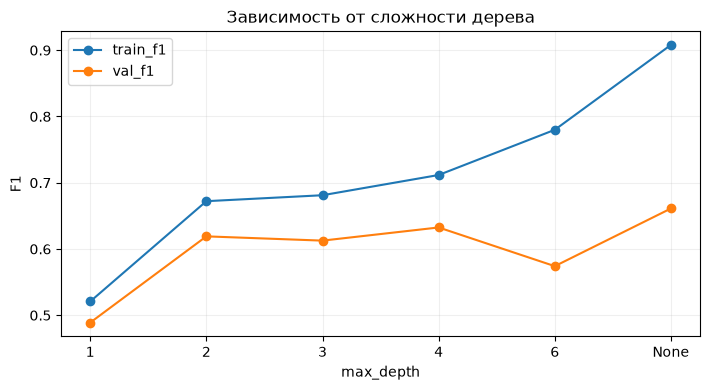

Лучшая глубина на validation: None, F1=0.661, листьев=67.
Худшая глубина на validation: 1, F1=0.489, листьев=2.
Без ограничения глубины: F1(train)=0.908, F1(val)=0.661; разрыв=0.247.


In [8]:
depth_rows=[]
for depth in [1,2,3,4,6,None]:
    p = build_pipeline(DecisionTreeClassifier(max_depth=depth,
                                               min_samples_leaf=3,random_state=42))
    p.fit(Xtrain,ytrain)
    depth_rows.append({
        'max_depth': str(depth), 'leaves': p.named_steps['clf'].get_n_leaves(),
        'train_f1': f1_score(ytrain,p.predict(Xtrain),zero_division=0),
        'val_f1': f1_score(yval,p.predict(Xval),zero_division=0)})
depth_tbl=pd.DataFrame(depth_rows)
display(depth_tbl.round(3))
ax=depth_tbl.plot(x='max_depth',y=['train_f1','val_f1'], marker='o', figsize=(7.2,4))
ax.set(xlabel='max_depth',ylabel='F1',title='Зависимость от сложности дерева')
ax.grid(alpha=0.2);plt.tight_layout();plt.savefig('11_tree_depth.png',dpi=160);plt.show()
depth_tbl.to_csv('11_tree_depth.csv',index=False)
best_depth = depth_tbl.loc[depth_tbl['val_f1'].idxmax()]
worst_depth = depth_tbl.loc[depth_tbl['val_f1'].idxmin()]
print(f"Лучшая глубина на validation: {best_depth['max_depth']}, "
      f"F1={best_depth['val_f1']:.3f}, листьев={best_depth['leaves']}.")
print(f"Худшая глубина на validation: {worst_depth['max_depth']}, "
      f"F1={worst_depth['val_f1']:.3f}, листьев={worst_depth['leaves']}.")
deep = depth_tbl.iloc[-1]
print(f"Без ограничения глубины: F1(train)={deep['train_f1']:.3f}, "
      f"F1(val)={deep['val_f1']:.3f}; разрыв={deep['train_f1']-deep['val_f1']:.3f}.")


## 6. Визуализировать дерево и обсудить важность признаков (72–84 мин)
Покажите не более двух уровней ветвлений и объясните смысл одного правила. Значимость `feature_importances_` для леса — статистика разбиений обученного леса; она **не доказывает причинность** и может быть смещена. Используйте названия признаков *после* кодирования.

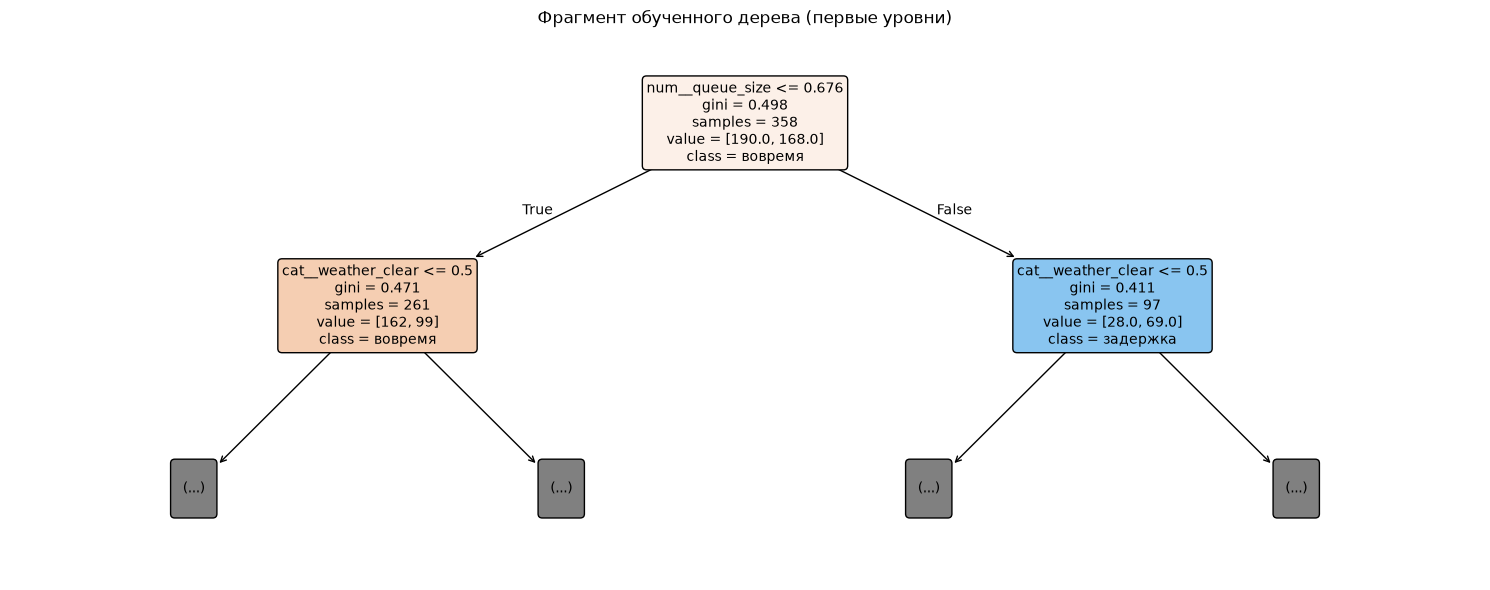

,feature,importance
1,num__queue_size,0.192994
3,num__promised_minutes,0.173311
6,num__planned_speed_kmh,0.142359
0,num__distance_km,0.133874
5,num__hour_cos,0.090183
4,num__hour_sin,0.081104
15,cat__weather_clear,0.080248
17,cat__weather_snow,0.024980


Сумма важностей: 1.0
Решение в узле 0: num__queue_size <= 0.676; левая ветвь n=261, P(late)=0.379; правая n=97, P(late)=0.711.
Решение в узле 1: cat__weather_clear <= 0.500; левая ветвь n=101, P(late)=0.535; правая n=160, P(late)=0.281.
Решение в узле 8: cat__weather_clear <= 0.500; левая ветвь n=42, P(late)=0.857; правая n=55, P(late)=0.600.
Важность отражает снижение неоднородности в обученном лесе; причинный эффект из неё не следует.


In [9]:
from sklearn.tree import plot_tree
fig,ax=plt.subplots(figsize=(15,6))
m=models['Tree']
fn=m.named_steps['prep'].get_feature_names_out()
plot_tree(m.named_steps['clf'],feature_names=fn,class_names=['вовремя','задержка'],
          max_depth=1,filled=True,rounded=True,fontsize=10,ax=ax)
ax.set_title('Фрагмент обученного дерева (первые уровни)')
plt.tight_layout();plt.savefig('11_tree_rules.png',dpi=160);plt.show()
forest = models['Forest']
imp = pd.DataFrame({'feature':forest.named_steps['prep'].get_feature_names_out(),
                    'importance':forest.named_steps['clf'].feature_importances_})
display(imp.nlargest(8,'importance'))
imp = imp.sort_values('importance', ascending=False)
print('Сумма важностей:', round(imp['importance'].sum(), 6))
tree = m.named_steps['clf'].tree_
for node in [0, int(tree.children_left[0]), int(tree.children_right[0])]:
    if node < 0 or tree.feature[node] < 0:
        continue
    left, right = tree.children_left[node], tree.children_right[node]
    print(f"Решение в узле {node}: {fn[tree.feature[node]]} <= {tree.threshold[node]:.3f}; "
          f"левая ветвь n={tree.n_node_samples[left]}, P(late)={tree.value[left,0,1]/tree.value[left,0].sum():.3f}; "
          f"правая n={tree.n_node_samples[right]}, P(late)={tree.value[right,0,1]/tree.value[right,0].sum():.3f}.")
print('Важность отражает снижение неоднородности в обученном лесе; причинный эффект из неё не следует.')


## 7. Вопросы и сдача (84–90 мин)
1. Запишите формулу индекса Джини и объясните, при каком распределении классов неопределённость выше.
2. Чем одно дерево принципиально отличается от случайного леса?
3. Почему бустинг последовательно исправляет ошибки, а случайный лес усредняет независимые деревья?
4. Почему валидатор может показать хуже результаты, чем train?
5. Чем AP отличается от ROC-AUC и от точности классификации?
6. Почему нельзя отбирать лучшую глубину по test?

**Сдача:** `11_student.ipynb`, отчёт `Группа_Фамилия_З11_Отчёт.pdf/docx`, `11_validation_models.csv`, `11_tree_depth.csv`, два графика PNG. Обязательно выполнить «Перезапуск → Выполнить все».

**Ответы для самопроверки.**
1. Gini(p)=1−p²−(1−p)²=2p(1−p); максимум 0,5 при p=0,5.
2. Одно дерево — одна последовательность правил; лес усредняет много деревьев, построенных на случайных подвыборках и подмножествах признаков.
3. Лес строит деревья параллельно и усредняет прогнозы; бустинг добавляет деревья последовательно, уменьшая потери предыдущего ансамбля.
4. Разница F1(train) и F1(val) возникает, когда модель запоминает особенности обучения, которые не повторяются на новых заказах. Для вывода используем значения таблицы глубин.
5. AP оценивает ранжирование положительного класса на PR-кривой, ROC-AUC — отделение классов по всему диапазону порогов, а accuracy — долю верных бинарных решений при выбранном пороге. При редком классе ROC-AUC может выглядеть приемлемо, хотя число ложных тревог делает модель малополезной.
6. Выбор глубины по test подгоняет решение под отложенную оценку и делает её оптимистичной; подбор выполняется по validation. Важность признака в дереве/лесе не является доказательством причинности.
